# 기능 D Y 왼쪽 검은 띠 처리 비교 (10/30)

16 Y(`yahoo-inc/photo-background-generation`) 원출력 33장 중 12장의 왼쪽 가장자리에 검은 띠가 생겼다(가장자리 16px 밝기 평균 20 미만). 띠는 패딩이 아닌 곳에도 생긴다: mug_02·studio는 가로 사진이라 패딩이 위아래인데 왼쪽에 띠가 있다(16 원출력 `y_raw/Y__mug_02__studio.png`). 패딩 부분은 모델 카드 코드상 마스크 255(다시 그림)이고 파이프라인이 `masked_image = image * (mask < 0.5)`로 지우므로 패딩 색은 원인이 아니다. 원인을 고치는 대신 서비스에서 쓸 처리 방법을 비교한다.

| 후보 | 방식 |
|---|---|
| 다시 생성 | 띠가 있으면 seed를 바꿔 다시 생성 (seed 0 → 1 → 2, 최대 3번). seed 0은 16 결과를 그대로 쓰고 seed 1·2를 새로 만든다 |
| 잘라내기 | 띠가 있는 쪽을 띠 폭만큼 잘라냄 (후처리, 화면 비율이 바뀜) |

- 띠 판정: 결과 이미지 가장자리(왼·오·위·아래) 16px 밝기 평균이 20 미만이고 이미지 전체 평균이 60 넘음 (16 확인 때 쓴 기준). 띠 폭은 가장자리부터 열(행) 밝기 평균이 20 미만인 연속 개수
- 판정 대상: 원출력(512×512, 패딩 포함)과 최종 결과(패딩을 걷어 키우고 원본 굿즈를 덮은 것) 둘 다. 서비스에서 보이는 것은 최종 결과다.
- 그 밖의 설정은 16 Y와 같다(입력 `outputs/background_relight/_in/`, 장면 문구, 20스텝, ControlNet 1.0, `torch.autocast`, 원본 굿즈 다시 덮기).
- 지표: 띠 비율(seed별), 다시 생성 횟수별 띠 없는 비율(seed 0 → 1 → 2 순서), 잘라낼 때 잘리는 폭 비율, 장면 문구 CLIP 유사도(16과 같음)
- 기록 (`outputs/background_y_band/`)
  - `yb_config.json`, `yb_records.csv`(이미지 1장마다 seed·시간·최대 VRAM·오류), `yb_runs.csv`
  - `yb_scored.csv`(이미지마다 띠 판정·폭·장면 점수), `yb_summary.csv`, `yb_band.png`, `yb_grid.png`
- 진행 출력: 생성은 별도 프로세스에서 하고, 모델 로드 시작·끝과 장마다 `[시각 | 경과 | VRAM] i/전체`를 바로 출력한다.
- 예상 시간: 66장(seed 2개 × 33장) × 16 장당 2.31초 ≈ 2.5분 + 모델 로드(16 첫 실행 102.1초, 다운로드 포함) ≈ 5분(추정). 새로 받는 모델 없음.
- GPU를 다른 노트북과 동시에 쓰지 않는다.

## 설정

In [1]:
import json
import os
import platform
import subprocess
import sys
import time
import importlib.metadata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

ROOT = Path('..')
REL_DIR = ROOT / 'outputs' / 'background_relight'
IN_DIR = REL_DIR / '_in'
OUT_DIR = ROOT / 'outputs' / 'background_y_band'
(OUT_DIR / 'y_raw').mkdir(parents=True, exist_ok=True)
REC_CSV = OUT_DIR / 'yb_records.csv'
RUNS_CSV = OUT_DIR / 'yb_runs.csv'

GOODS_DIR = ROOT / 'data' / 'raw' / 'goods'
GOODS = pd.read_csv(GOODS_DIR / 'goods_sources.csv', keep_default_na=False)
GOODS = GOODS[(GOODS.error == '') & GOODS.file.map(lambda f: (GOODS_DIR / f).exists())].reset_index(drop=True)
KIND_EN = {'tshirt': 't-shirt', 'hoodie': 'hoodie', 'tote': 'tote bag', 'mug': 'mug'}
# 16과 같은 장면 문구·Y 설정
SCENES = {
    'desk': 'on a wooden desk next to a game controller and small figures, warm desk lamp light, cozy room',
    'studio': 'on a pastel color studio backdrop, soft shadow, clean background',
    'cafe': 'on a cafe table by the window, morning sunlight, shallow depth of field',
}
Y_REPO = 'yahoo-inc/photo-background-generation'
Y_ARGS = dict(size=512, steps=20, cond_scale=1.0, guess_mode=False)
SEEDS = [0, 1, 2]       # 0은 16 결과
NEW_SEEDS = [1, 2]
DARK, EDGE_PX = 20, 16  # 16 확인 때 쓴 띠 판정 기준


def scene_prompt(kind, scene):
    return f'product photography of a {KIND_EN[kind]} {SCENES[scene]}'


def name(seed, goods, scene):
    st = Path(goods).stem
    return f'Y__{st}__{scene}.png' if seed == 0 else f'Y_s{seed}__{st}__{scene}.png'


def paths(seed, goods, scene):
    # (최종, 원출력)
    d = REL_DIR if seed == 0 else OUT_DIR
    return d / name(seed, goods, scene), d / 'y_raw' / name(seed, goods, scene)


need = [IN_DIR / f'{Path(g).stem}__{sc}{s}.png' for g in GOODS.file for sc in SCENES for s in ['', '_mask']]
need += [p for g in GOODS.file for sc in SCENES for p in paths(0, g, sc)]
miss = [str(p) for p in need if not p.exists()]
assert not miss, f'16 Y 입력·결과가 없음: {miss[:3]}'
print('굿즈', len(GOODS), '장 × 장면', len(SCENES), '| 새로 만들 seed', NEW_SEEDS)

recs = {x['file']: x for x in pd.read_csv(REC_CSV, keep_default_na=False).to_dict('records')} if REC_CSV.exists() else {}


def done(f):
    return recs.get(f, {}).get('error', 'x') == '' and (OUT_DIR / f).exists()


def save_rec(rec):
    recs[rec['file']] = rec
    pd.DataFrame(list(recs.values())).to_csv(REC_CSV, index=False, encoding='utf-8-sig')


def pkg_version(n):
    try:
        return importlib.metadata.version(n)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


# 멈춤 여부를 바로 알 수 있게 시각·경과를 함께 출력 (생성 프로세스는 VRAM도 출력)
def log(msg, t_start=None):
    el = ''
    if t_start is not None:
        m, sec = divmod(int(time.perf_counter() - t_start), 60)
        el = f' | 경과 {m // 60:d}:{m % 60:02d}:{sec:02d}'
    print(f'[{time.strftime("%H:%M:%S")}{el}] {msg}', flush=True)


def band(path):
    # 가장자리별 띠 폭(px)과 판정. 띠: 가장자리 EDGE_PX 밝기 평균 < DARK, 전체 평균 > 60
    a = np.asarray(Image.open(path).convert('L'), dtype=np.float32)
    cols, rows = a.mean(0), a.mean(1)
    out = dict(width=a.shape[1], height=a.shape[0], mean=float(a.mean()))
    for side, v in [('left', cols), ('right', cols[::-1]), ('top', rows), ('bottom', rows[::-1])]:
        dark = v < DARK
        out[f'{side}_px'] = int(len(dark) if dark.all() else np.argmin(dark))
        out[f'{side}_band'] = bool(v[:EDGE_PX].mean() < DARK and a.mean() > 60)
    out['band'] = any(out[f'{s}_band'] for s in ['left', 'right', 'top', 'bottom'])
    return out

굿즈 11 장 × 장면 3 | 새로 만들 seed [1, 2]


## 생성 (seed 1·2, 별도 프로세스)

In [2]:
CHILD_Y = r"""
import csv, json, os, sys, time
import numpy as np
import torch
from PIL import Image, ImageOps

a = json.loads(sys.stdin.read())
T0 = time.perf_counter()


def log(msg):
    m, s = divmod(int(time.perf_counter() - T0), 60)
    vr = f' | VRAM {torch.cuda.memory_allocated() / 1024**3:.1f}GB (최대 {torch.cuda.max_memory_allocated() / 1024**3:.1f}GB)'
    print(f'[{time.strftime("%H:%M:%S")} | 경과 {m // 60:d}:{m % 60:02d}:{s:02d}{vr}] {msg}', flush=True)


def resize_with_padding(img, expected_size):
    # 모델 카드 코드 그대로
    img.thumbnail((expected_size[0], expected_size[1]))
    delta_width = expected_size[0] - img.size[0]
    delta_height = expected_size[1] - img.size[1]
    pad_width = delta_width // 2
    pad_height = delta_height // 2
    padding = (pad_width, pad_height, delta_width - pad_width, delta_height - pad_height)
    return ImageOps.expand(img, padding), padding


# 저장소 pipeline.py(diffusers 0.27 기준)의 옛 경로 → 현재 diffusers의 같은 모듈
import diffusers.models.controlnets.multicontrolnet as _mc
sys.modules.setdefault('diffusers.pipelines.controlnet.multicontrolnet', _mc)
from diffusers import DiffusionPipeline

log('Y 로드 시작 (첫 실행이면 다운로드 포함)')
pipe = DiffusionPipeline.from_pretrained(a['repo'], custom_pipeline=a['repo'], trust_remote_code=True).to('cuda')
pipe.set_progress_bar_config(disable=True)
load_sec = round(time.perf_counter() - T0, 1)
log(f'Y 로드 끝 {load_sec}초 | {type(pipe).__name__}')
FIELDS = ['file', 'method', 'goods', 'kind', 'scene', 'params', 'sec', 'peak_vram_gb', 'load_sec', 'error']
S = a['size']
for i, t in enumerate(a['tasks'], 1):
    rec = {k: t.get(k, '') for k in FIELDS}
    rec['load_sec'] = load_sec
    try:
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        goods = Image.open(t['goods_path']).convert('RGB')
        fg = Image.open(t['mask_path']).convert('L')
        img, pad = resize_with_padding(goods.copy(), (S, S))
        m, _ = resize_with_padding(fg.copy(), (S, S))
        mask = ImageOps.invert(m)
        g = torch.Generator(device='cuda').manual_seed(t['seed'])
        with torch.autocast('cuda'):
            out = pipe(prompt=t['prompt'], image=img, mask_image=mask, control_image=mask, num_images_per_prompt=1, generator=g,
                       num_inference_steps=a['steps'], guess_mode=a['guess_mode'],
                       controlnet_conditioning_scale=a['cond_scale']).images[0]
        out.save(t['raw_out'])
        # 패딩을 걷어내고 원래 틀로 키운 뒤 원본 굿즈를 마스크 알파로 다시 덮어씀
        box = (pad[0], pad[1], S - pad[2], S - pad[3])
        big = np.asarray(out.crop(box).resize(goods.size, Image.LANCZOS), dtype=np.float32)
        al = np.asarray(fg, dtype=np.float32)[..., None] / 255
        res = np.asarray(goods, dtype=np.float32) * al + big * (1 - al)
        Image.fromarray(res.round().clip(0, 255).astype(np.uint8)).save(t['out'])
        rec['sec'] = round(time.perf_counter() - t1, 2)
        rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:300]
    new = not os.path.exists(a['csv'])
    with open(a['csv'], 'a', newline='', encoding='utf-8') as fh:
        w = csv.DictWriter(fh, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow(rec)
    log(f"Y {i}/{len(a['tasks'])} {t['file']} {rec.get('sec')}초 {rec['error'][:100]}")
"""

todo = [(g, sc, s) for s in NEW_SEEDS for g in GOODS.itertuples() for sc in SCENES if not done(name(s, g.file, sc))]
log(f'새로 만들 이미지 {len(todo)}장')
if todo:
    started, t_all = time.strftime('%Y-%m-%d %H:%M:%S'), time.perf_counter()
    tasks = []
    for g, sc, s in todo:
        st = f'{Path(g.file).stem}__{sc}'
        f = name(s, g.file, sc)
        tasks.append(dict(file=f, method=f'Y_s{s}', goods=g.file, kind=g.kind, scene=sc, seed=s, prompt=scene_prompt(g.kind, sc),
                          goods_path=str((IN_DIR / f'{st}.png').resolve()), mask_path=str((IN_DIR / f'{st}_mask.png').resolve()),
                          out=str((OUT_DIR / f).resolve()), raw_out=str((OUT_DIR / 'y_raw' / f).resolve()),
                          params=json.dumps(dict(Y_ARGS, repo=Y_REPO, seed=s, prompt=scene_prompt(g.kind, sc)))))
    tmp = OUT_DIR / 'y_child.csv'
    tmp.unlink(missing_ok=True)
    proc = subprocess.Popen([sys.executable, '-c', CHILD_Y], stdin=subprocess.PIPE, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True, encoding='utf-8', errors='replace',
                            env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    proc.stdin.write(json.dumps(dict(repo=Y_REPO, seed=0, csv=str(tmp.resolve()), tasks=tasks, **Y_ARGS)))
    proc.stdin.close()
    # 진행 상황을 셀 출력에 바로 보여 줌
    for line in proc.stdout:
        print(line, end='', flush=True)
    rc = proc.wait()
    got = pd.read_csv(tmp, keep_default_na=False).to_dict('records') if tmp.exists() else []
    for x in got:
        save_rec(dict(x, seed=int(x['params'] and json.loads(x['params'])['seed'])))
    for t in tasks:
        if t['file'] not in {x['file'] for x in got}:
            save_rec({k: t[k] for k in ['file', 'method', 'goods', 'kind', 'scene', 'seed', 'params']} | dict(error=f'프로세스 종료 코드 {rc}'))
    peaks = [float(x['peak_vram_gb']) for x in got if x['peak_vram_gb'] != '']
    pd.DataFrame([dict(started=started, ended=time.strftime('%Y-%m-%d %H:%M:%S'), sec_total=round(time.perf_counter() - t_all, 1),
                       n_new=sum(x['error'] == '' for x in got), load_sec=got[0]['load_sec'] if got else None,
                       peak_vram_gb=max(peaks) if peaks else None, returncode=rc)]).to_csv(
        RUNS_CSV, mode='a', header=not RUNS_CSV.exists(), index=False, encoding='utf-8-sig')
    log(f'종료 코드 {rc} | 새로 만든 장수 {sum(x["error"] == "" for x in got)}', t_all)
(OUT_DIR / 'yb_config.json').write_text(json.dumps(dict(
    saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), seeds=SEEDS, seed0_from=str(REL_DIR), y=dict(repo=Y_REPO, **Y_ARGS), scenes=SCENES,
    band_rule=dict(dark=DARK, edge_px=EDGE_PX, image_mean_over=60), goods=GOODS[['file', 'kind']].to_dict('records'),
    versions={p: pkg_version(p) for p in ['torch', 'diffusers', 'transformers', 'accelerate', 'pillow', 'numpy']},
    python=platform.python_version(), gpu=gpu_info()), ensure_ascii=False, indent=1), encoding='utf-8')
yr = pd.read_csv(REC_CSV, keep_default_na=False)
print('기록', len(yr), '장 | 오류', (yr.error != '').sum())

[17:47:59] 새로 만들 이미지 66장
Multiple distributions found for package optimum. Picked distribution: optimum
W1030 17:48:24.011000 48132 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1030 17:48:24.100000 48132 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
[17:48:27 | 경과 0:00:24 | VRAM 0.0GB (최대 0.0GB)] Y 로드 시작 (첫 실행이면 다운로드 포함)

Loading pipeline components...:  29%|██▊       | 2/7 [00:00<00:01,  3.18it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?i

## 띠 판정·지표

In [3]:
from transformers import CLIPModel, CLIPProcessor

# 16과 같은 CLIP
CLIP_ID = 'openai/clip-vit-base-patch32'
clip = CLIPModel.from_pretrained(CLIP_ID).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


def unit(e):
    # transformers 5.x: get_*_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output
    e = (e.pooler_output if hasattr(e, 'pooler_output') else e).float().numpy()
    return e / np.linalg.norm(e, axis=1, keepdims=True)


with torch.no_grad():
    SCENE_E = dict(zip(SCENES, unit(clip.get_text_features(**clip_proc(text=list(SCENES.values()), return_tensors='pt',
                                                                         padding=True, truncation=True)))))
rows, t_all = [], time.perf_counter()
for g in GOODS.itertuples():
    for sc in SCENES:
        for s in SEEDS:
            fin, raw = paths(s, g.file, sc)
            if not (fin.exists() and raw.exists()):
                continue
            bf, br = band(fin), band(raw)
            with torch.no_grad():
                e = unit(clip.get_image_features(**clip_proc(images=[Image.open(fin).convert('RGB')], return_tensors='pt')))[0]
            rows.append(dict(goods=g.file, kind=g.kind, scene=sc, seed=s, file=fin.name, band_final=bf['band'], band_raw=br['band'],
                             **{f'final_{k}': v for k, v in bf.items() if k != 'band'}, **{f'raw_{k}': v for k, v in br.items() if k != 'band'},
                             scene_sim=float(e @ SCENE_E[sc])))
log(f'판정 {len(rows)}장', t_all)
ys = pd.DataFrame(rows)
# 잘라내기: 띠가 있는 쪽을 띠 폭만큼 자를 때 잘리는 가로(세로) 비율
ys['crop_frac'] = np.where(ys.band_final, np.maximum(
    (ys.final_left_px * ys.final_left_band + ys.final_right_px * ys.final_right_band) / ys.final_width,
    (ys.final_top_px * ys.final_top_band + ys.final_bottom_px * ys.final_bottom_band) / ys.final_height), 0.0)
ys.to_csv(OUT_DIR / 'yb_scored.csv', index=False, encoding='utf-8-sig')

per_seed = ys.groupby('seed').agg(n=('file', 'size'), band_raw=('band_raw', 'mean'), band_final=('band_final', 'mean'),
                                  scene_sim=('scene_sim', 'mean'))
# 다시 생성: seed 0 → 1 → 2 순서로 띠 없는 첫 결과를 씀
piv = ys.pivot_table(index=['goods', 'scene'], columns='seed', values='band_final', aggfunc='first')
ok_by = {k: float((~piv[SEEDS[:k]].all(axis=1)).mean()) for k in range(1, len(SEEDS) + 1) if set(SEEDS[:k]) <= set(piv.columns)}
first_ok = piv.apply(lambda r: next((s for s in SEEDS if s in r and r[s] == False), None), axis=1)
summary = per_seed.copy()
summary['ok_within_tries'] = [ok_by.get(i + 1) for i in range(len(summary))]
summary.to_csv(OUT_DIR / 'yb_summary.csv', encoding='utf-8-sig')
display(summary.round(3))
print('다시 생성 횟수별 띠 없는 비율 (seed 0 → 1 → 2):', {f'{k}번': round(v, 3) for k, v in ok_by.items()})
print('3번 안에 띠 없는 결과가 없는 경우:', list(first_ok[first_ok.isna()].index))
b0 = ys[(ys.seed == 0) & ys.band_final]
print(f'seed 0 띠 {len(b0)}장 | 잘라내기 폭 비율 평균 {b0.crop_frac.mean():.3f}, 최대 {b0.crop_frac.max():.3f}')
display(ys[ys.band_final][['goods', 'scene', 'seed', 'final_left_px', 'final_right_px', 'final_top_px', 'final_bottom_px', 'crop_frac']])

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1030 17:51:21.267000 48980 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1030 17:51:21.484000 48980 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 18878.09it/s]


[17:51:34 | 경과 0:00:09] 판정 99장


,n,band_raw,band_final,scene_sim,ok_within_tries
seed,,,,,
0,33,0.364,0.364,0.247,0.636
1,33,0.061,0.030,0.243,0.970
2,33,0.000,0.000,0.249,1.000


다시 생성 횟수별 띠 없는 비율 (seed 0 → 1 → 2): {'1번': 0.636, '2번': 0.97, '3번': 1.0}
3번 안에 띠 없는 결과가 없는 경우: []
seed 0 띠 12장 | 잘라내기 폭 비율 평균 0.107, 최대 0.173


,goods,scene,seed,final_left_px,final_right_px,final_top_px,final_bottom_px,crop_frac
3,mug_01.jpg,studio,0,141,0,0,0,0.148109
6,mug_01.jpg,cafe,0,24,0,0,0,0.025210
9,mug_02.jpg,desk,0,147,0,0,0,0.143555
12,mug_02.jpg,studio,0,177,0,0,0,0.172852
15,mug_02.jpg,cafe,0,107,0,0,0,0.104492
42,tshirt_01.jpg,cafe,0,31,0,0,0,0.030273
45,tshirt_02.jpg,desk,0,51,0,0,0,0.049805
51,tshirt_02.jpg,cafe,0,162,0,0,0,0.158203
52,tshirt_02.jpg,cafe,1,0,15,0,0,0.014648
54,tote_01.jpg,desk,0,176,0,0,0,0.171875


## 시각화

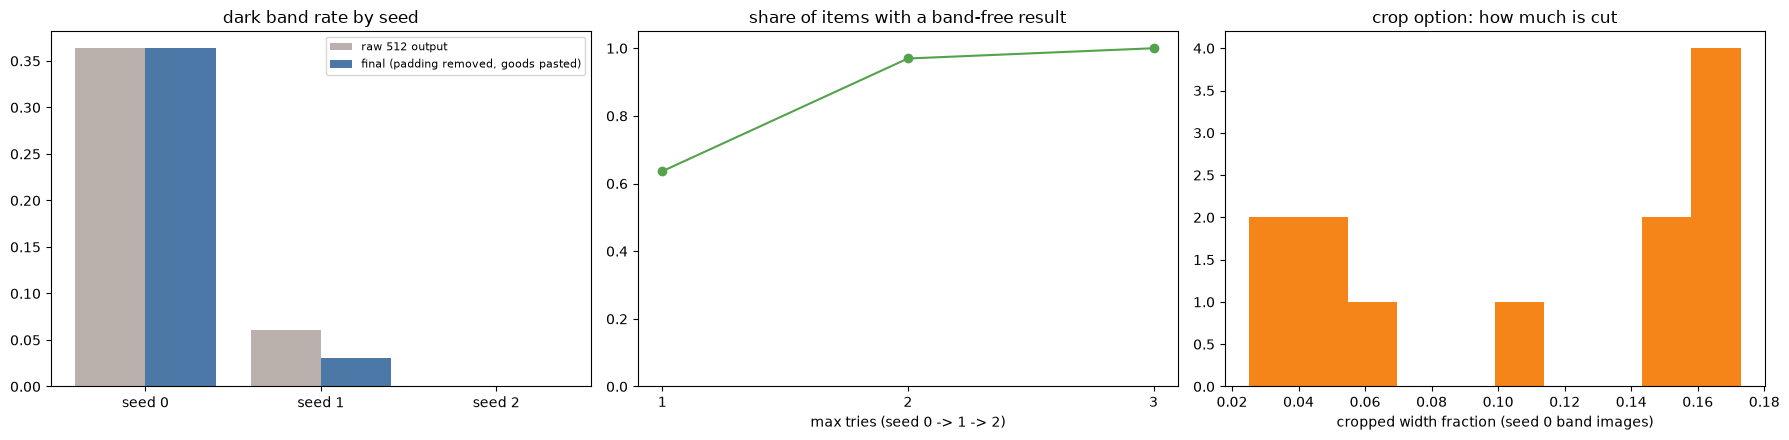

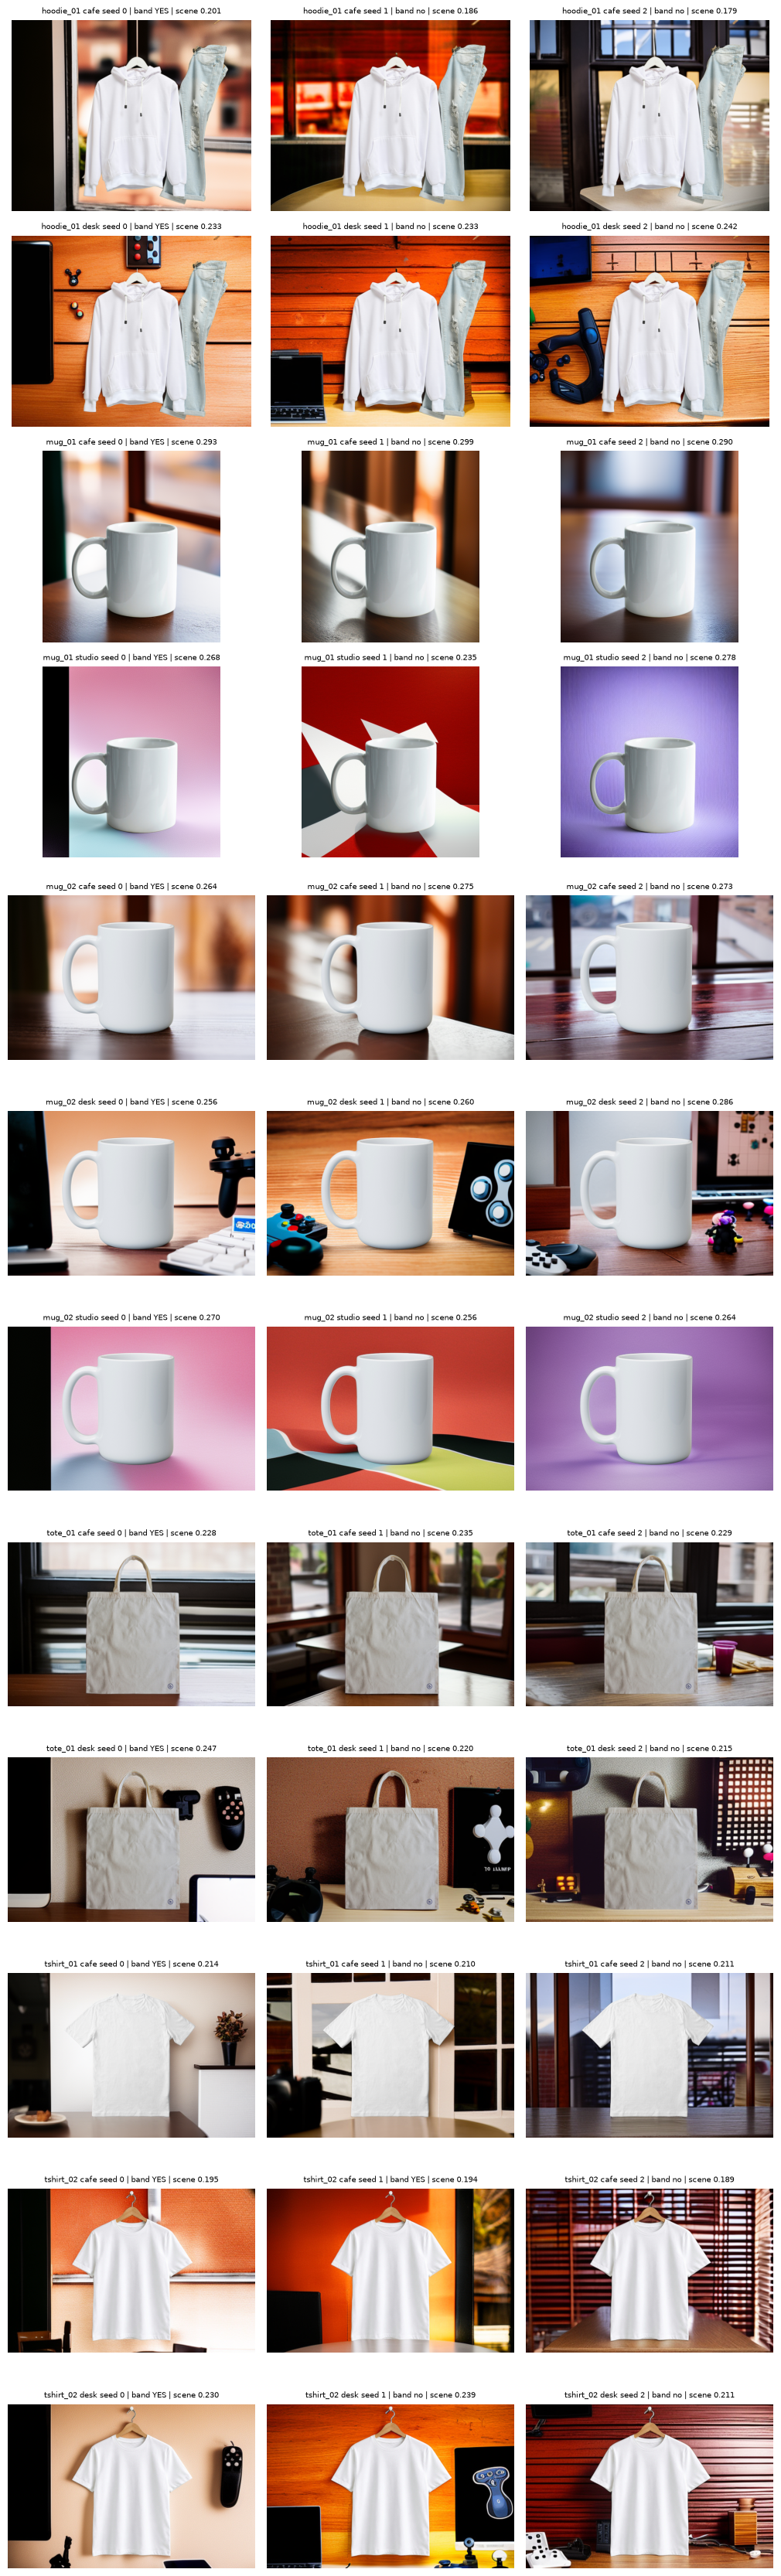

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
x = np.arange(len(per_seed))
axes[0].bar(x - 0.2, per_seed.band_raw, 0.4, label='raw 512 output', color='#BAB0AC')
axes[0].bar(x + 0.2, per_seed.band_final, 0.4, label='final (padding removed, goods pasted)', color='#4C78A8')
axes[0].set_xticks(x, [f'seed {s}' for s in per_seed.index])
axes[0].set_title('dark band rate by seed')
axes[0].legend(fontsize=8)
axes[1].plot(list(ok_by), list(ok_by.values()), marker='o', color='#54A24B')
axes[1].set_xticks(list(ok_by))
axes[1].set_ylim(0, 1.05)
axes[1].set_xlabel('max tries (seed 0 -> 1 -> 2)')
axes[1].set_title('share of items with a band-free result')
axes[2].hist(b0.crop_frac, bins=10, color='#F58518')
axes[2].set_xlabel('cropped width fraction (seed 0 band images)')
axes[2].set_title('crop option: how much is cut')
plt.tight_layout()
plt.savefig(OUT_DIR / 'yb_band.png', dpi=80)
plt.show()

# 띠가 생긴 굿즈·장면: 행 = 굿즈·장면, 열 = seed 0·1·2 최종 결과
keys = sorted({(r.goods, r.scene) for r in ys[ys.band_final].itertuples()})
if keys:
    fig, axes = plt.subplots(len(keys), len(SEEDS), figsize=(3.4 * len(SEEDS), 2.8 * len(keys)), squeeze=False)
    for i, (gname, sc) in enumerate(keys):
        for j, s in enumerate(SEEDS):
            ax = axes[i, j]
            ax.axis('off')
            r = ys[(ys.goods == gname) & (ys.scene == sc) & (ys.seed == s)]
            if len(r):
                r = r.iloc[0]
                ax.imshow(Image.open(paths(s, gname, sc)[0]))
                ax.set_title(f"{Path(gname).stem} {sc} seed {s} | band {'YES' if r.band_final else 'no'} | scene {r.scene_sim:.3f}", fontsize=7)
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'yb_grid.png', dpi=50)
    plt.show()